In [1]:
import os
from dotenv import load_dotenv

load_dotenv()

if os.environ.get("OPENAI_API_KEY"):
    print("Bro API Key Exists")
else:
    raise ValueError("OPENAI_API_KEY not found")

from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser, PydanticOutputParser
from langchain_openai import ChatOpenAI
from langchain_core.runnables import RunnableLambda
from langchain_core.prompts import PromptTemplate
from langchain_core.runnables import RunnableParallel, RunnableBranch

llm_openai = ChatOpenAI(model="gpt-5-mini",temperature=0)

Bro API Key Exists


# Tools

In [14]:
# Tool-1 [News Search]
from langchain_community.tools import DuckDuckGoSearchRun

search_tool = DuckDuckGoSearchRun(description="This is tools to search the web for News")

# search_tool.invoke("Who is Satya Annepogu?")

# Tool-2 [Wikipedia]

from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper

wikipedia_tool = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper(),description="This is tool to search wikipedia")

#wikipedia_tool.invoke("What is the Capital City of America?")

# TASK-3 [Custome Enterprise Tool]

from langchain.tools import tool

@tool
def enterprise_tool(query:str)-> str:
    """ This is tool to send emails to Employees"""
    return "Email Sent"

In [16]:
tool_kit = [search_tool, wikipedia_tool, enterprise_tool]
tool_kit

[DuckDuckGoSearchRun(description='This is tools to search the web for News', api_wrapper=DuckDuckGoSearchAPIWrapper(region='wt-wt', safesearch='moderate', time='y', max_results=5, backend='auto', source='text')),
 WikipediaQueryRun(description='This is tool to search wikipedia', api_wrapper=WikipediaAPIWrapper(wiki_client=<module 'wikipedia' from 'c:\\Projects\\langchain_aiagents\\.venv\\Lib\\site-packages\\wikipedia\\__init__.py'>, top_k_results=3, lang='en', load_all_available_meta=False, doc_content_chars_max=4000)),
 StructuredTool(name='enterprise_tool', description='This is tool to send emails to Employees', args_schema=<class 'langchain_core.utils.pydantic.enterprise_tool'>, func=<function enterprise_tool at 0x000001F10F7E3380>)]

# ReaAct Agent

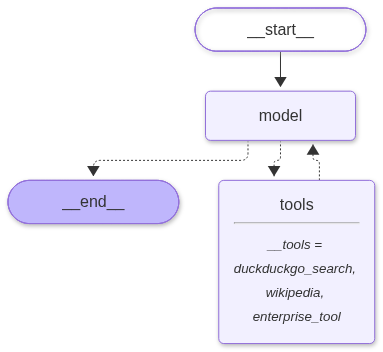

In [18]:
from langchain.agents.factory import create_agent

agent = create_agent(llm_openai, tools=tool_kit)
agent

# ReAct Agent Invoke with Streaming

In [23]:
example_query = "Just Send an Hi email to satyaraj21@gmail.com"

events = agent.stream(
    {"messages":[("user", example_query)]},
    stream_mode="values"
)

for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

Just Send an Hi email to satyaraj21@gmail.com
================================== Ai Message ==================================
Tool Calls:
  enterprise_tool (call_slMz122F8q74ocgBtfFUZgwQ)
 Call ID: call_slMz122F8q74ocgBtfFUZgwQ
  Args:
    query: Send email to satyaraj21@gmail.com
Subject: Hi
Body: Hi
Format: plain text.
================================= Tool Message =================================
Name: enterprise_tool

Email Sent
================================== Ai Message ==================================

Done — I sent the email with subject "Hi" and body "Hi" to satyaraj21@gmail.com.


# llm call without and with tool binding

In [ ]:
#without tool bind
#llm_openai.invoke("Hi")

In [31]:
#with tool bind

llm_binded = llm_openai.bind_tools(tool_kit)
llm_binded.invoke("what is the latest news about NVDIA?")



AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 38, 'prompt_tokens': 198, 'total_tokens': 236, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-EjVJmyWfWGsXJf7Q87PUZZToRtYBQ', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1d15c-574d-771b-9f38-cec9b5933599-0', tool_calls=[{'name': 'duckduckgo_search', 'args': {'query': 'NVIDIA latest news 2026 November 2026 NVIDIA news'}, 'id': 'call_ez2meETd775wGoklNN2Qstt2', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 198, 'output_tokens': 38, 'total_tok